# HRP walk-forward allocation

Original project: Spark Hu, November 2025. Technical corrections prepared with Codex assistance on 5 October 2026. Documentation revised on 18 October 2026.

HRP invests in MSFT, GOOG, JPM, XLE and GLD. SPY is excluded from fitting and provides market context. Equal weighting uses the same assets and execution assumptions as HRP. The original MVO notebook uses a different universe, so this is not a matched MVO-versus-HRP test.

## 1. Common return observations

The 2020 data supply the first 252-observation training window. We keep complete common prices before computing simple returns. The first test block starts only after the lookback and a one-observation signal delay.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display, Image
from pypfopt import HRPOpt
from allocation import prepare_prices, simple_returns, hold_block, fixed_weight_returns
from fetch_data import load_snapshot
from run_analysis import HRP_TICKERS, RESULTS, run_hrp
RESULTS.mkdir(exist_ok=True)
raw = load_snapshot()
prices = prepare_prices(raw, HRP_TICKERS + ['SPY'], start='2020-01-01', end='2025-01-01')
all_returns = simple_returns(prices)
investable = all_returns.loc[:, HRP_TICKERS]
display(investable.head())
print('Common prices:', len(prices), 'returns:', len(all_returns))

,MSFT,GOOG,JPM,XLE,GLD
Date,,,,,
2020-01-03,-0.012452,-0.004907,-0.013197,-0.002971,0.013269
2020-01-06,0.002585,0.024657,-0.000795,0.007781,0.010490
2020-01-07,-0.009118,-0.000624,-0.017000,-0.002628,0.003935
2020-01-08,0.015928,0.007881,0.007801,-0.016472,-0.007502
2020-01-09,0.012493,0.011044,0.003651,0.007369,-0.005652


Common prices: 1258 returns: 1257


## 2. First allocation and information timing

HRP forms correlation distances $d_{i,j}=\sqrt{(1-\rho_{i,j})/2}$, clusters the assets, orders them and recursively allocates using cluster variances. It still uses historical covariance estimates.

Below, the last training return ends before the execution close. The first test return runs from that execution close to the following observation. The library's `single` linkage is specified explicitly.

In [2]:
window, lag = 252, 1
first_test = window + lag
train_end = first_test - lag
train = investable.iloc[train_end-window:train_end]
model = HRPOpt(train)
first_weights = pd.Series(model.optimize(linkage_method='single')).reindex(HRP_TICKERS)
display(first_weights.to_frame('first_target_weight'))
display(train.corr())
print('Latest training return:', train.index[-1].date())
print('Execution close:', investable.index[first_test-1].date())
print('First evaluated return:', investable.index[first_test].date())

,first_target_weight
MSFT,0.136509
GOOG,0.114278
JPM,0.031118
XLE,0.025194
GLD,0.692901


,MSFT,GOOG,JPM,XLE,GLD
MSFT,1.000000,0.852445,0.586700,0.516816,0.150511
GOOG,0.852445,1.000000,0.595414,0.579080,0.145479
JPM,0.586700,0.595414,1.000000,0.825600,-0.039252
XLE,0.516816,0.579080,0.825600,1.000000,0.013924
GLD,0.150511,0.145479,-0.039252,0.013924,1.000000


Latest training return: 2020-12-31
Execution close: 2021-01-04
First evaluated return: 2021-01-05


## 3. Holding-period accounting

Both assets start at half the capital. Asset A doubles on day 1 and B doubles on day 2. Holding the original positions ends at wealth 2; restoring 50/50 each day ends at 2.25. These are different trading rules. The corrected HRP test uses drifting holdings within its 21-observation blocks.

In [3]:
toy = pd.DataFrame({'A': [1.0, 0.0], 'B': [0.0, 1.0]})
toy_weights = pd.Series({'A': 0.5, 'B': 0.5})
held_returns, final_weights = hold_block(toy, toy_weights)
daily_restored = fixed_weight_returns(toy, toy_weights)
display(pd.DataFrame({'holding_wealth': (1+held_returns).cumprod(),
                      'daily_restored_wealth': (1+daily_restored).cumprod()}))

,holding_wealth,daily_restored_wealth
0,1.5,1.50
1,2.0,2.25


## 4. Rolling experiment and cost sensitivity

Each target update uses 252 past return observations, a one-observation signal delay and a 21-observation holding block. Equal weighting uses the same schedule. SPY is bought and held over the same evaluation dates.

The second cost case charges 5 bps per dollar traded, including initial purchases. Buying and selling both count. This is an illustrative proportional charge; it does not claim full execution realism. Costs do not change fitted target weights in this experiment.

,strategy,cost_bps_per_traded_dollar,annualized_compound_growth_252,annualized_volatility,sharpe_daily_excess,maximum_drawdown
0,HRP,0,0.124102,0.122933,0.694203,-0.178800
1,Equal weight (same assets),0,0.216128,0.160147,1.057349,-0.200583
2,SPY buy and hold,0,0.139531,0.164767,0.637277,-0.244964
3,HRP,5,0.123354,0.122930,0.688797,-0.179021
4,Equal weight (same assets),5,0.215648,0.160142,1.054914,-0.200708
5,SPY buy and hold,5,0.139388,0.164762,0.636528,-0.244964


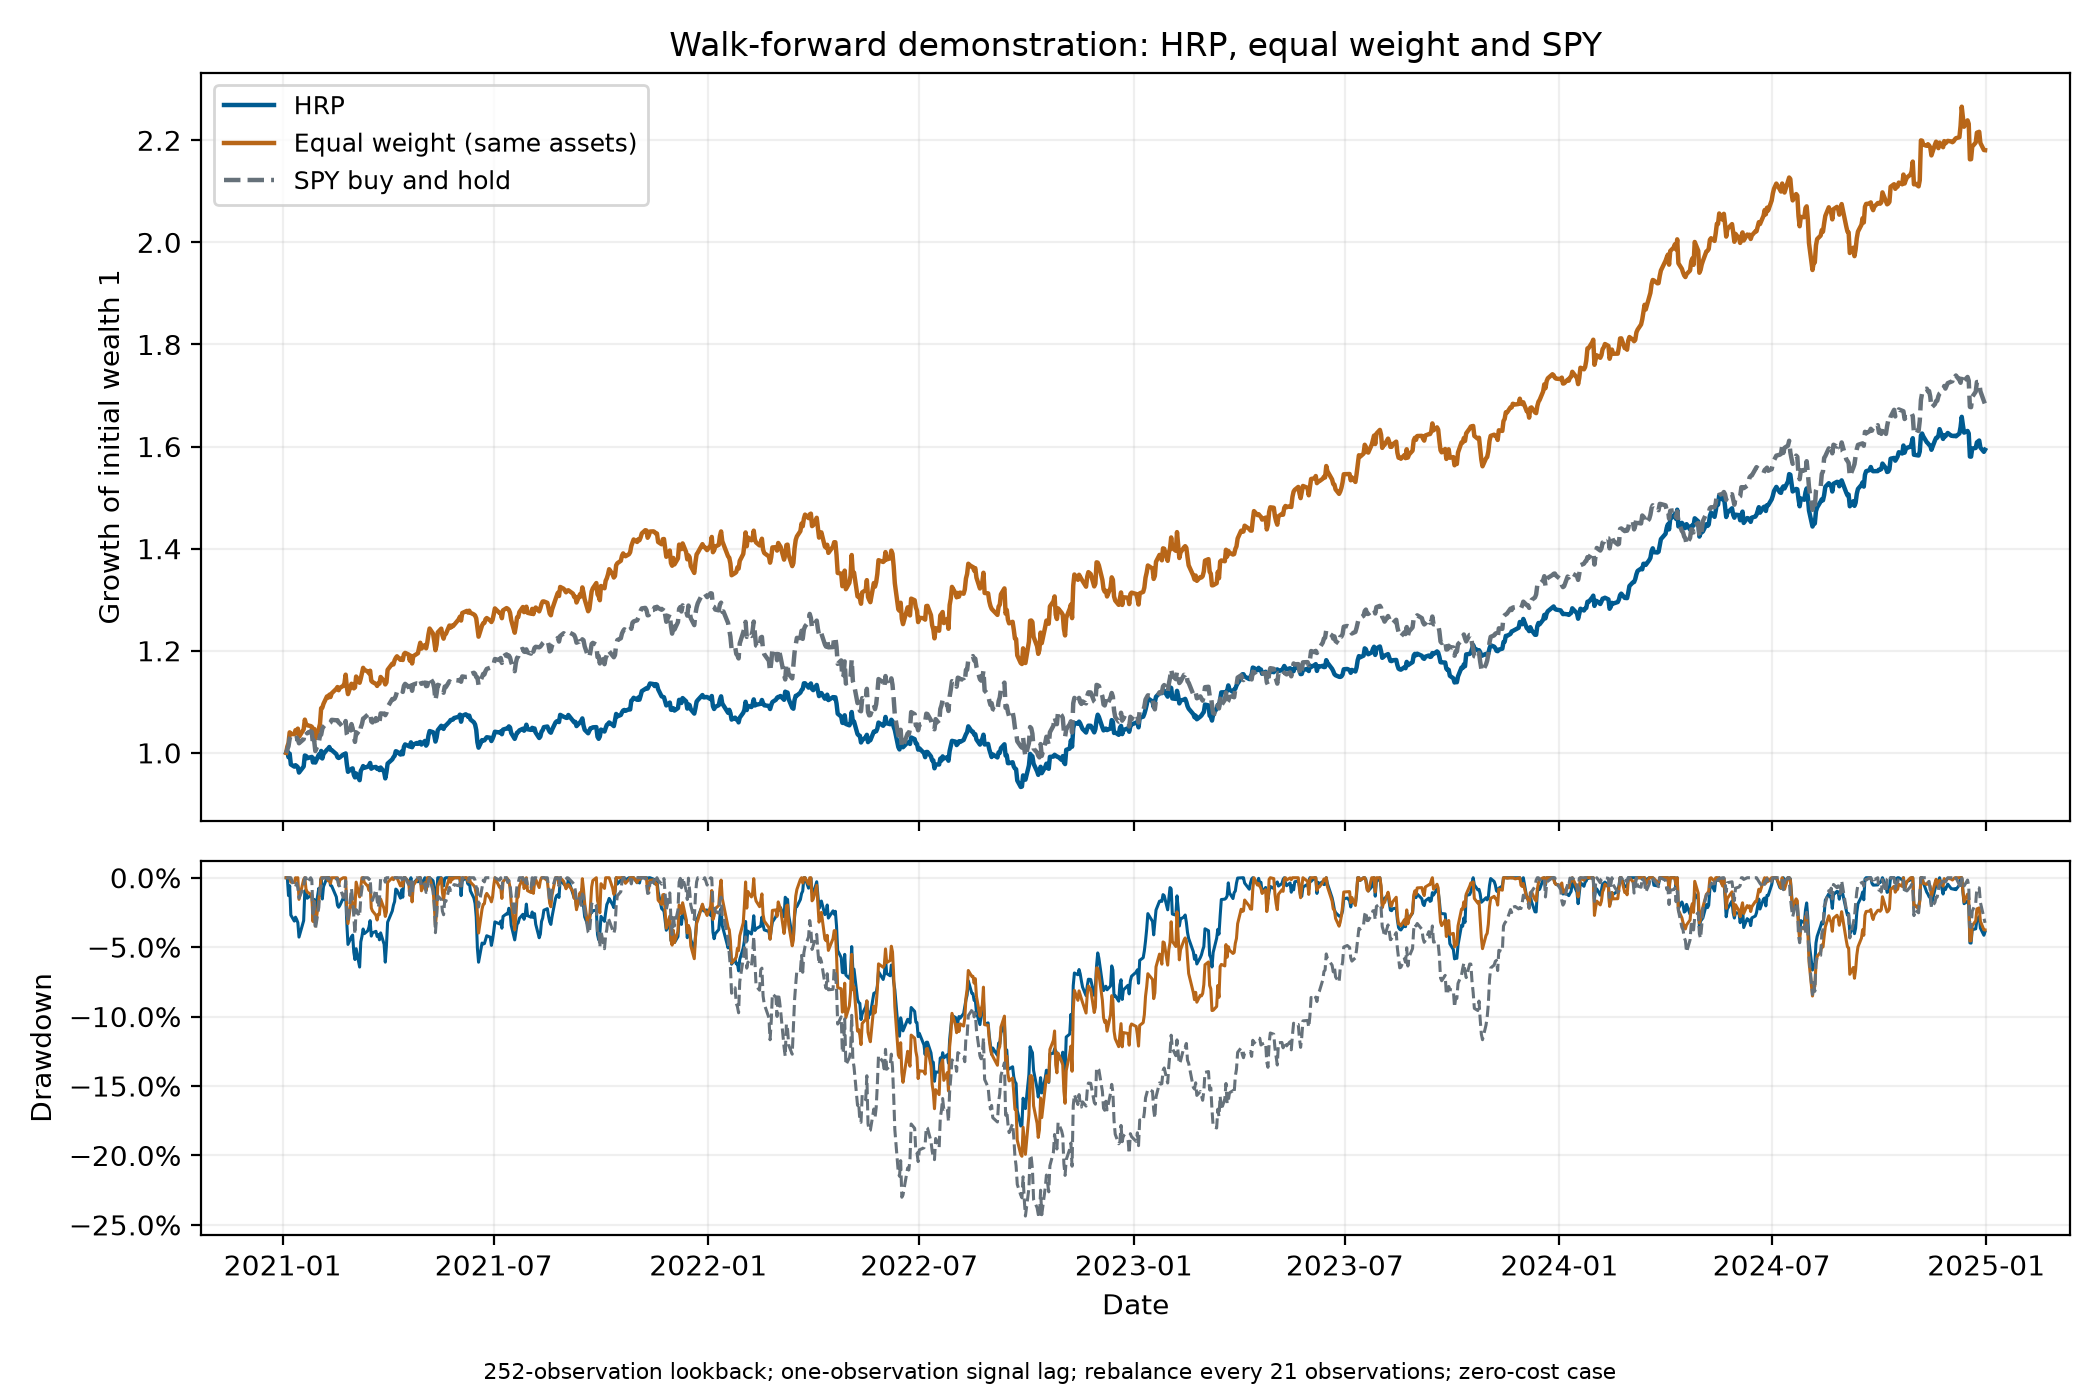

In [4]:
result = run_hrp(raw)
metrics = pd.DataFrame(result['metrics'])
selected = ['strategy', 'cost_bps_per_traded_dollar',
            'annualized_compound_growth_252', 'annualized_volatility',
            'sharpe_daily_excess', 'maximum_drawdown']
display(metrics[selected])
display(Image(filename=str(RESULTS / 'Walk_Forward_Backtest.png')))

## 5. Rebalance chronology and interpretation

The saved log contains the training window, execution close, subsequent test dates and trade sizes. Drawdown calculations include initial wealth. Compound growth and arithmetic mean are kept separate.

Measured differences describe this historical sample under these assumptions. No statistical significance, guaranteed future risk reduction or general HRP superiority over MVO is established.

In [5]:
log = pd.read_csv(RESULTS / 'hrp-rebalances-0bps.csv')
display(log.head())
print('Allocation updates including initial investment:', len(log))
print('Total traded fraction of portfolio wealth:', log['traded_weight'].sum())

,training_start,training_end,execution_close,first_test_date,last_test_date,test_observations,traded_weight,cost_fraction
0,2020-01-03T00:00:00,2020-12-31T00:00:00,2021-01-04T00:00:00,2021-01-05T00:00:00,2021-02-03T00:00:00,21,1.000000,0.0
1,2020-02-04T00:00:00,2021-02-02T00:00:00,2021-02-03T00:00:00,2021-02-04T00:00:00,2021-03-05T00:00:00,21,0.066611,0.0
2,2020-03-05T00:00:00,2021-03-04T00:00:00,2021-03-05T00:00:00,2021-03-08T00:00:00,2021-04-06T00:00:00,21,0.034906,0.0
3,2020-04-03T00:00:00,2021-04-05T00:00:00,2021-04-06T00:00:00,2021-04-07T00:00:00,2021-05-05T00:00:00,21,0.207886,0.0
4,2020-05-05T00:00:00,2021-05-04T00:00:00,2021-05-05T00:00:00,2021-05-06T00:00:00,2021-06-04T00:00:00,21,0.309328,0.0


Allocation updates including initial investment: 48
Total traded fraction of portfolio wealth: 5.3072742771854315
